# Team: Gradient Capital
**Members:** Prisha, Mariia

## Milestone 1: baseline and a simple model

The goal is to predict the S&P 500's (SPY) volatility regime over the next 5 trading days (calm / middle / crisis), as well as its realized volatility over that period. The models use recent daily SPY price data as input.
We start with zero-parameter baselines and a small 1D CNN. All models are evaluated on the same 2020-2023 test days.

**Run:** `pip install -r requirements.txt && pip install -e .`, then run all cells.
The notebook uses the dataset included in the repository `data/processed/table.parquet`, so no additional downloads are needed.
Seeds are fixed and PyTorch runs in deterministic mode, so every number below is the same on every run.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, sklearn
from sklearn.metrics import confusion_matrix
from dl_fin import config as C
from dl_fin.datasets import FEATURE_SETS, fit_stats, split_days
from dl_fin.baselines import majority, persistence
from dl_fin.labels.vol_regime import cutoffs
from dl_fin.metrics import score
from dl_fin.models import CNN, n_params
from dl_fin.train import fit, predict

FIG, RES = C.ROOT / "figures", C.ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
SEARCH_SEEDS, FINAL_SEEDS = [0, 1, 2], [0, 1, 2, 3, 4]
REGIMES = ["calm", "middle", "crisis"]
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

torch 2.8.0 | numpy 2.0.2 | pandas 2.3.3 | sklearn 1.6.1


## 1. Data

**Sources.** SPY daily prices and volume from yfinance; CPI, the 10Y-2Y Treasury spread and the fed funds rate from FRED. The macroeconomic variables are shifted to account for publication lags, so the model only uses information that would have been available at the time. The data is collected and processed using `scripts/01`-`03`, and the resulting dataset is included in the repository as a snapshot.

**Features.** Each row represents one trading day.  The input features include daily log returns, 21-day realized volatility, log trading volume, volume relative to its trailing one-year average, the daily high-low price range, and the three macroeconomic indicators.

**Targets.** `fwd_rv` = realized volatility of the next 5 daily returns (t+1 .. t+5), annualized.
`regime` buckets `fwd_rv` at the 50th and 87th percentiles of the train split: calm / middle / crisis.

**Train, validation, and test sets.** Train 2009-05 to 2017, validation 2018-2019, test 2020-2023, no shuffling.
The last 5 days of each split are dropped so no target overlaps the next split.
For each prediction, the model looks at a window of recent trading days ending on the target day, which can include days before the start of a particular split. Features and the log-transformed volatility target are standardized using statistics from the training set.

In [2]:
table = pd.read_parquet(C.PROCESSED / "table.parquet")
print(table.shape, table.index.min().date(), "->", table.index.max().date())
cols = ["Close", "log_ret", "rv_21", "rel_volume", "hl_range", "cpi_yoy", "t10y2y", "fedfunds", "rv_5", "fwd_rv", "regime"]
pd.concat([table[cols].loc["2019-12-31":].head(3), table[cols].loc["2020-03-16":].head(2)]).round(4)

(4773, 16) 2006-01-06 -> 2024-12-23


,Close,log_ret,rv_21,rel_volume,hl_range,cpi_yoy,t10y2y,fedfunds,rv_5,fwd_rv,regime
date,,,,,,,,,,,
2019-12-31,292.6549,0.0024,0.0749,-0.1422,0.0062,2.0923,0.32,1.55,0.0635,0.1072,1
2020-01-02,295.3918,0.0093,0.0706,-0.1034,0.0073,2.0923,0.34,1.55,0.0891,0.0966,0
2020-01-03,293.1549,-0.0076,0.0721,0.1719,0.0079,2.0923,0.30,1.55,0.1066,0.0727,0
2020-03-16,218.0864,-0.1159,0.7659,1.4734,0.0791,2.5998,0.45,1.58,1.4138,0.6724,2
2020-03-17,229.8613,0.0526,0.8004,1.3417,0.0775,2.3413,0.37,1.58,1.4212,0.8916,2


In [3]:
cuts = cutoffs(table.fwd_rv)
print("regime cutoffs (annualized vol):", cuts.round(4))
split_summary = pd.DataFrame({s: table.loc[split_days(table, s), "regime"].value_counts().sort_index()
                              for s in ["train", "val", "test"]}).T
split_summary.columns = REGIMES
split_summary["days"] = split_summary.sum(1)
split_summary["first"] = [split_days(table, s)[0].date() for s in split_summary.index]
split_summary["last"] = [split_days(table, s)[-1].date() for s in split_summary.index]
split_summary.to_csv(RES / "split_summary.csv")
split_summary

regime cutoffs (annualized vol): [0.1061 0.2125]


,calm,middle,crisis,days,first,last
train,1086,808,284,2178,2009-05-01,2017-12-21
val,281,145,72,498,2018-01-02,2019-12-23
test,292,453,256,1001,2020-01-02,2023-12-21


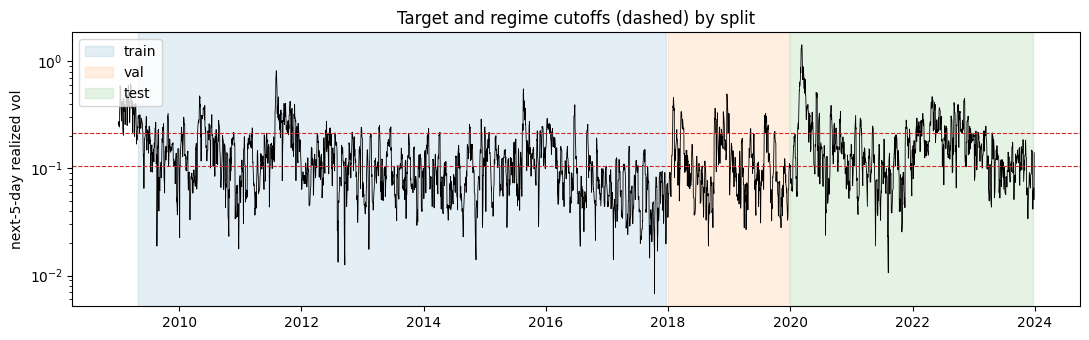

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))
t = table.loc["2009":"2023"]
ax.plot(t.index, t.fwd_rv, lw=0.6, color="k")
for c in cuts:
    ax.axhline(c, ls="--", lw=0.8, color="tab:red")
for s, col in zip(["train", "val", "test"], ["tab:blue", "tab:orange", "tab:green"]):
    d = split_days(table, s)
    ax.axvspan(d[0], d[-1], alpha=0.12, color=col, label=s)
ax.set_ylabel("next-5-day realized vol"); ax.set_yscale("log"); ax.legend(loc="upper left")
ax.set_title("Target and regime cutoffs (dashed) by split")
fig.tight_layout(); fig.savefig(FIG / "data_overview.png", dpi=150)

In [5]:
from hmmlearn.hmm import GaussianHMM

# old labels: 3-state HMM on (log return, 21-day vol), fit on the train years only
X = table[["log_ret", "rv_21"]].values
is_tr = table.index <= "2017-12-31"
Z = (X - X[is_tr].mean(0)) / X[is_tr].std(0)
hmm = GaussianHMM(3, covariance_type="full", n_iter=500, random_state=0).fit(Z[is_tr])
hmm_regime = pd.Series(hmm.predict(Z), index=table.index)
same = (hmm_regime.shift(-1) == hmm_regime)[:-1]
print(f"HMM labels: tomorrow = today on {same.mean():.1%} of days ({same.loc['2020':'2023'].mean():.1%} in 2020-2023)")

news_days = pd.read_parquet(C.PROCESSED / "news_count.parquet").index    # trading days with at least one article
window = table.loc[news_days.min():news_days.max()].index
print(f"news: {news_days.min().date()} to {news_days.max().date()}, on {window.isin(news_days).mean():.1%} of trading days in that window")

HMM labels: tomorrow = today on 97.7% of days (97.4% in 2020-2023)
news: 2009-04-29 to 2024-01-09, on 98.5% of trading days in that window


## 2. Baselines (0 parameters)

- **Majority:** always the most common train regime (calm) and the train median of forward vol.
- **Persistence:** the next 5 days look like the last 5: predict the trailing 5-day realized vol and its regime.

In [6]:
test_days = split_days(table, "test")
y_reg, y_vol = table.loc[test_days, "regime"].values, table.loc[test_days, "fwd_rv"].values
preds = {"majority": majority(table, test_days), "persistence": persistence(table, test_days)}
rows = {name: {"params": 0, **score(y_reg, p_reg, y_vol, p_vol)} for name, (p_reg, p_vol) in preds.items()}
pd.DataFrame(rows).T.round(4)

,params,macro_f1,crisis_recall,accuracy,vol_mae,vol_rmse
majority,0.0,0.1506,0.0000,0.2917,0.0927,0.1646
persistence,0.0,0.5429,0.5742,0.5415,0.0775,0.1160


## 3. Simple model: 1D CNN

Input: the last `window` days of features, shape (window, n_features).
Two Conv1d layers (kernel 5, ReLU, max-pool 2) -> flatten -> dropout 0.2 -> linear(32) + ReLU -> two heads:
3 regime logits and one standardized log-vol value.
Loss = class-weighted cross-entropy (inverse train frequency) + MSE on standardized log vol.
Adam (weight decay 1e-4), batch 64, up to 100 epochs, early stopping on validation loss (patience 10, best weights restored).

In [7]:
print(CNN(n_feat=4, window=60, ch=32))
for f in FEATURE_SETS:
    for w in (20, 60):
        print(f"{f:13s} window={w}: ch=16 -> {n_params(CNN(len(FEATURE_SETS[f]), w, 16)):,} params, "
              f"ch=32 -> {n_params(CNN(len(FEATURE_SETS[f]), w, 32)):,} params")

CNN(
  (conv): Sequential(
    (0): Conv1d(4, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.2, inplace=False)
    (2): Linear(in_features=480, out_features=32, bias=True)
    (3): ReLU()
  )
  (regime_head): Linear(in_features=32, out_features=3, bias=True)
  (vol_head): Linear(in_features=32, out_features=1, bias=True)
)
price+macro   window=20: ch=16 -> 4,596 params, ch=32 -> 11,588 params
price+macro   window=60: ch=16 -> 9,716 params, ch=32 -> 21,828 params
price         window=20: ch=16 -> 4,356 params, ch=32 -> 11,108 params
price         window=60: ch=16 -> 9,476 params, ch=32 -> 21,348 params
price_relvol  window=20: ch=16 ->

## 4. Hyperparameter search (validation set only)

Grid: feature set x window {20, 60} x channels {16, 32} x learning rate {1e-3, 3e-4}, 3 seeds each.
Selection criterion: the lowest average of the best validation losses across the three runs. The test set is not used here.

First a check on the inputs: measure this in standard deviations relative to the training data, to see whether the model has feature values that are unusual compared with what it was trained on.

In [8]:
st = fit_stats(table, FEATURE_SETS["price+macro"] + ["rel_volume"])
shift = {}
for s in ["val", "test"]:
    z = (table.loc[split_days(table, s), st["features"]] - st["x_mean"]) / st["x_std"]
    shift[s + "_min_z"], shift[s + "_max_z"] = z.min(), z.max()
pd.DataFrame(shift).round(1)

,val_min_z,val_max_z,test_min_z,test_max_z
log_ret,-4.6,5.2,-12.3,9.1
rv_21,-1.3,2.6,-1.0,11.6
log_volume,-2.6,2.1,-3.1,2.3
hl_range,-1.2,5.8,-1.2,10.9
cpi_yoy,0.0,1.2,-1.1,6.5
t10y2y,-2.9,-1.6,-4.6,-0.3
fedfunds,3.4,8.1,-0.7,18.9
rel_volume,-1.9,4.5,-2.8,4.9


In [9]:
rows = []
for feats in FEATURE_SETS:
    st = fit_stats(table, FEATURE_SETS[feats])
    va_days = split_days(table, "val")
    va_reg, va_vol = table.loc[va_days, "regime"].values, table.loc[va_days, "fwd_rv"].values
    for window in (20, 60):
        for ch in (16, 32):
            for lr in (1e-3, 3e-4):
                for seed in SEARCH_SEEDS:
                    model, hist = fit(table, st, window, ch, lr, seed)
                    p_reg, p_vol = predict(model, table, st, "val", window)
                    m = score(va_reg, p_reg, va_vol, p_vol)
                    rows.append({"features": feats, "window": window, "ch": ch, "lr": lr, "seed": seed,
                                 "val_loss": hist.val_loss.min(), "best_epoch": int(hist.val_loss.idxmin()) + 1,
                                 "val_macro_f1": m["macro_f1"], "val_vol_mae": m["vol_mae"]})
search = pd.DataFrame(rows)
search.to_csv(RES / "hparam_search_runs.csv", index=False)
summary = (search.groupby(["features", "window", "ch", "lr"])
           .agg(val_loss=("val_loss", "mean"), val_loss_std=("val_loss", "std"), val_macro_f1=("val_macro_f1", "mean"),
                val_vol_mae=("val_vol_mae", "mean"), best_epoch=("best_epoch", "mean"))
           .reset_index().sort_values("val_loss"))
summary.to_csv(RES / "hparam_search.csv", index=False)
summary.round(4)

,features,window,ch,lr,val_loss,val_loss_std,val_macro_f1,val_vol_mae,best_epoch
17,price_relvol,20,16,0.0010,1.3627,0.0462,0.5784,0.0447,13.6667
16,price_relvol,20,16,0.0003,1.3688,0.0499,0.5636,0.0448,28.6667
19,price_relvol,20,32,0.0010,1.3776,0.0254,0.5827,0.0449,8.0000
18,price_relvol,20,32,0.0003,1.4000,0.0384,0.5743,0.0452,20.3333
2,price,20,32,0.0003,1.4086,0.0168,0.5813,0.0459,23.6667
1,price,20,16,0.0010,1.4161,0.0324,0.5790,0.0455,9.3333
3,price,20,32,0.0010,1.4253,0.0129,0.5860,0.0461,8.3333
0,price,20,16,0.0003,1.4274,0.0198,0.5601,0.0453,21.6667
5,price,60,16,0.0010,1.5265,0.0362,0.5470,0.0491,7.6667
21,price_relvol,60,16,0.0010,1.5528,0.0231,0.5480,0.0487,6.0000


In [10]:
best = summary.iloc[0]
BEST = {"features": best.features, "window": int(best.window), "ch": int(best.ch), "lr": float(best.lr)}
print("selected:", BEST)
print("by feature set (best config each):")
summary.groupby("features").val_loss.min().round(4)

selected: {'features': 'price_relvol', 'window': 20, 'ch': 16, 'lr': 0.001}
by feature set (best config each):


features
price           1.4086
price+macro     2.1215
price_relvol    1.3627
Name: val_loss, dtype: float64

## 5. Final model: selected config, 5 seeds

params: 4356


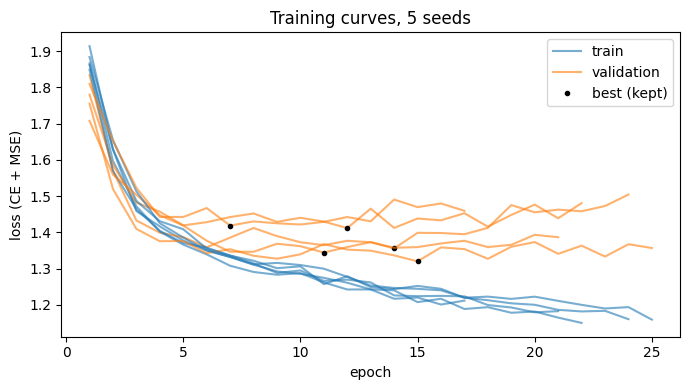

In [11]:
st = fit_stats(table, FEATURE_SETS[BEST["features"]])
print("params:", n_params(CNN(len(st["features"]), BEST["window"], BEST["ch"])))
models, hists = {}, {}
for seed in FINAL_SEEDS:
    models[seed], hists[seed] = fit(table, st, BEST["window"], BEST["ch"], BEST["lr"], seed)
pd.concat(hists, names=["seed", "epoch"]).to_csv(RES / "training_curves.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for seed, h in hists.items():
    ep = np.arange(1, len(h) + 1)
    ax.plot(ep, h.train_loss, color="tab:blue", alpha=0.6, label="train" if seed == 0 else None)
    ax.plot(ep, h.val_loss, color="tab:orange", alpha=0.6, label="validation" if seed == 0 else None)
    ax.plot(h.val_loss.idxmin() + 1, h.val_loss.min(), "k.", label="best (kept)" if seed == 0 else None)
ax.set_xlabel("epoch"); ax.set_ylabel("loss (CE + MSE)"); ax.legend()
ax.set_title(f"Training curves, {len(FINAL_SEEDS)} seeds")
fig.tight_layout(); fig.savefig(FIG / "training_curve.png", dpi=150)

## 6. Test results (2020-2023)

Metrics: macro-F1 over the three regimes (main), crisis recall (a missed crisis is the costly error), accuracy,
and MAE / RMSE of annualized forward vol. CNN is mean +- std over 5 seeds.

In [12]:
per_seed = []
for seed, model in models.items():
    p_reg, p_vol = predict(model, table, st, "test", BEST["window"])
    per_seed.append({"seed": seed, **score(y_reg, p_reg, y_vol, p_vol)})
    if seed == 0:
        preds["cnn"] = (p_reg, p_vol)
per_seed = pd.DataFrame(per_seed).set_index("seed")
per_seed.to_csv(RES / "test_cnn_per_seed.csv")

res = pd.DataFrame({name: {"params": 0, **score(y_reg, preds[name][0], y_vol, preds[name][1])}
                    for name in ["majority", "persistence"]}).T
res.loc["cnn"] = {"params": n_params(models[0]), **per_seed.mean()}
res.loc["cnn_std"] = {"params": np.nan, **per_seed.std()}
res.to_csv(RES / "test_results.csv")
res.round(4)

,params,macro_f1,crisis_recall,accuracy,vol_mae,vol_rmse
majority,0.0,0.1506,0.0000,0.2917,0.0927,0.1646
persistence,0.0,0.5429,0.5742,0.5415,0.0775,0.1160
cnn,4356.0,0.5866,0.7648,0.5812,0.0690,0.1294
cnn_std,NaN,0.0150,0.0230,0.0151,0.0025,0.0089


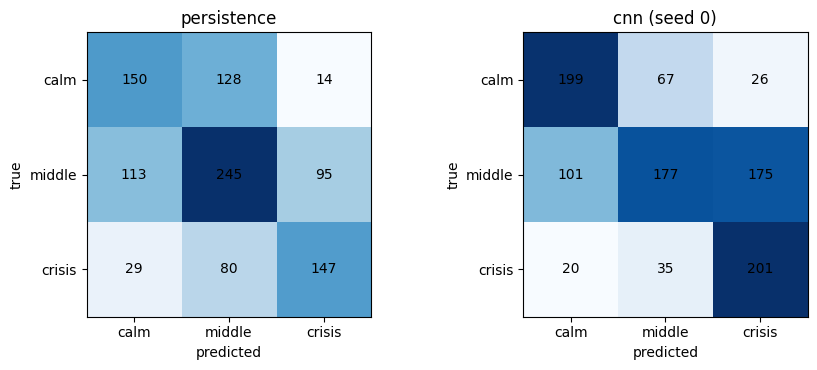

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, ["persistence", "cnn"]):
    cm = confusion_matrix(y_reg, preds[name][0], labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xticks(range(3), REGIMES); ax.set_yticks(range(3), REGIMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name + (" (seed 0)" if name == "cnn" else ""))
fig.tight_layout(); fig.savefig(FIG / "confusion.png", dpi=150)

,crisis_days,persistence,cnn
COVID,48.0,0.917,0.938
2022_bear,108.0,0.648,0.944
SVB,3.0,0.667,0.667


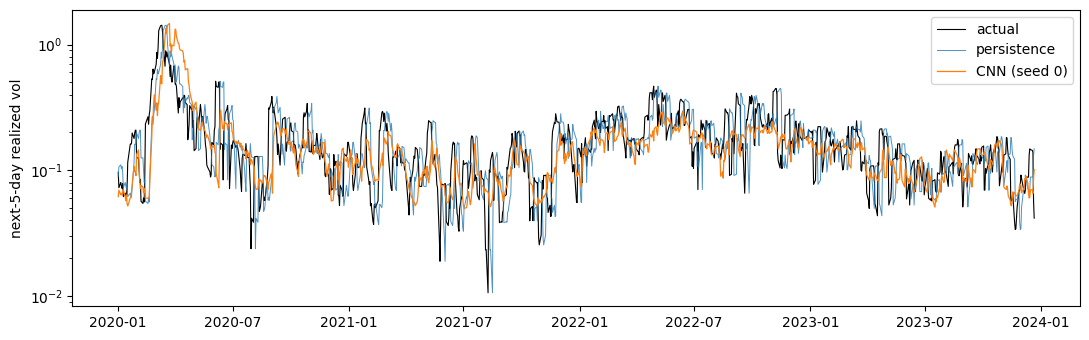

In [14]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(test_days, y_vol, color="k", lw=0.8, label="actual")
ax.plot(test_days, preds["persistence"][1], lw=0.7, alpha=0.8, label="persistence")
ax.plot(test_days, preds["cnn"][1], lw=0.9, label="CNN (seed 0)")
ax.set_yscale("log"); ax.set_ylabel("next-5-day realized vol"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "test_vol.png", dpi=150)

# crisis recall during known stress periods in the test window
periods = {k: v for k, v in C.CRISES.items() if k != "GFC"}
rec = {}
for k, (a, b) in periods.items():
    m = (test_days >= a) & (test_days <= b) & (y_reg == 2)
    rec[k] = {"crisis_days": int(m.sum()), **{n: (preds[n][0][m] == 2).mean() for n in ["persistence", "cnn"]}}
pd.DataFrame(rec).T.round(3)

## 7. Conclusion

The small 1D CNN (4,356 parameters, 20-day input window, using price and relative-volume features) performs better than both baselines on regime and volatility prediction. Its macro-F1 score is 0.587 ± 0.015, compared with 0.543 for the persistence baseline. It also achieves a lower volatility MAE (0.069 vs. 0.078) and identifies more crisis days. Most of this improvement can be attributed to the 2022 bear market, because during  COVID, the CNN performs approximately the same way as the persistence baseline. 

However, the CNN has a higher RMSE than persistence (0.129 vs. 0.116), which means that its predictions are smoother and it is less likely to capture sudden spikes in volatility.